Use Case 3 – Statistical Analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Set the project and database paths

In [2]:
PROJECT_DIR = Path.cwd().parent

DATABASE_FILE = (
    PROJECT_DIR / "database" / "chicago_crime.db"
)

print("Project directory:", PROJECT_DIR)
print("Database exists:", DATABASE_FILE.exists())

Project directory: c:\Users\sapni\OneDrive\Desktop\Chicago_Crime_Capstone
Database exists: True


Connect to SQLite and load the data

In [3]:
connection = sqlite3.connect(DATABASE_FILE)

query = """
SELECT
    c.case_number,
    c.date,
    c.iucr_code,
    i.PRIMARY_TYPE AS primary_type,
    c.arrest,
    c.domestic,
    c.beat_num,
    c.district_code,
    c.ward_no,
    c.community_code,
    cc.community_name,
    c.latitude,
    c.longitude,
    c.year,
    c.Month,
    c.DayOfWeek

FROM chicago_crime AS c

LEFT JOIN iucr AS i
    ON c.iucr_code = i.IUCR

LEFT JOIN city_community AS cc
    ON c.community_code = cc.community_code
"""

stats_df = pd.read_sql_query(query, connection)

print("Statistical analysis dataset loaded!")
print("Dataset shape:", stats_df.shape)

display(stats_df.head(10))

Statistical analysis dataset loaded!
Dataset shape: (498, 16)


,case_number,date,iucr_code,primary_type,arrest,domestic,beat_num,district_code,ward_no,community_code,community_name,latitude,longitude,year,Month,DayOfWeek
0,HZ250496,2016-05-03,486,BATTERY,1,1,1022,10,24,29,North Lawndale,41.864073,-87.706819,2016,5,Tuesday
1,HZ250409,2016-05-03,486,BATTERY,0,1,313,3,20,42,Woodlawn,41.782922,-87.604363,2016,5,Tuesday
2,HZ250503,2016-05-03,470,PUBLIC PEACE VIOLATION,0,0,1524,15,37,25,Austin,41.894908,-87.758372,2016,5,Tuesday
3,HZ250424,2016-05-03,460,BATTERY,0,0,1532,15,28,25,Austin,41.885687,-87.749516,2016,5,Tuesday
4,HZ250455,2016-05-03,820,THEFT,0,1,1523,15,28,25,Austin,41.886297,-87.761751,2016,5,Tuesday
5,HZ250447,2016-05-03,041A,BATTERY,0,0,631,6,8,44,Chatham,41.745354,-87.603799,2016,5,Tuesday
6,HZ250489,2016-05-03,460,BATTERY,0,0,133,1,3,35,Douglas,41.844024,-87.626923,2016,5,Tuesday
7,HZ250514,2016-05-03,460,BATTERY,0,0,215,2,3,38,Grand Boulevard,41.811134,-87.620741,2016,5,Tuesday
8,HZ250523,2016-05-03,460,BATTERY,0,0,2432,24,40,1,Rogers Park,41.998131,-87.665814,2016,5,Tuesday
9,HZ250667,2016-05-03,486,BATTERY,0,1,735,7,17,67,West Englewood,41.768097,-87.663879,2016,5,Tuesday


Prepare date and time columns

In [4]:
print("Sample date values:")
display(stats_df["date"].head(10))

print("\nDate data type:")
print(stats_df["date"].dtype)

Sample date values:


0    2016-05-03
1    2016-05-03
2    2016-05-03
3    2016-05-03
4    2016-05-03
5    2016-05-03
6    2016-05-03
7    2016-05-03
8    2016-05-03
9    2016-05-03
Name: date, dtype: str


Date data type:
str


convert the date column:

In [7]:
stats_df["date"] = pd.to_datetime(
    stats_df["date"],
    errors="coerce"
)

stats_df["Year"] = stats_df["date"].dt.year
stats_df["Month"] = stats_df["date"].dt.month
stats_df["Hour"] = stats_df["date"].dt.hour

print("Date and time columns prepared!")

display(
    stats_df[["date", "Year", "Month", "Hour"]].head(10)
)





Date and time columns prepared!


,date,Year,Month,Hour
0,2016-05-03,2016,5,0
1,2016-05-03,2016,5,0
2,2016-05-03,2016,5,0
3,2016-05-03,2016,5,0
4,2016-05-03,2016,5,0
5,2016-05-03,2016,5,0
6,2016-05-03,2016,5,0
7,2016-05-03,2016,5,0
8,2016-05-03,2016,5,0
9,2016-05-03,2016,5,0


All extracted hour values were 0 (midnight) because no actual time component was available.

Therefore, a meaningful hourly crime distribution could not be calculated.

Community-area statistical analysis

alculate average crime counts by community area and identify outliers.

In [8]:
# Calculate crime counts for each community area
community_stats = (
    stats_df
    .dropna(subset=["community_code", "community_name"])
    .groupby(
        ["community_code", "community_name"]
    )["case_number"]
    .count()
    .reset_index(name="Crime_Count")
)

# Display summary statistics
print("Community area statistics:")

display(
    community_stats["Crime_Count"].describe()
)

Community area statistics:


count    70.000000
mean      7.114286
std       5.857097
min       1.000000
25%       3.000000
50%       6.000000
75%       9.000000
max      34.000000
Name: Crime_Count, dtype: float64

In [9]:
# Calculate average crime count per community
average_community_crimes = community_stats["Crime_Count"].mean()

print(
    f"Average crimes per community area: "
    f"{average_community_crimes:.2f}"
)

Average crimes per community area: 7.11


Capstone interpretation:

The analysis identified 70 community areas with available crime records. The average number of recorded crimes per community was 7.11, while the median was 6. Crime counts ranged from 1 to 34, indicating variation in the distribution of recorded incidents across community areas.

Identify outliers using the IQR method
The assessment specifically requires us to identify community-area outliers using the Interquartile Range (IQR).

In [10]:
# Calculate quartiles
Q1 = community_stats["Crime_Count"].quantile(0.25)
Q3 = community_stats["Crime_Count"].quantile(0.75)

# Calculate interquartile range
IQR = Q3 - Q1

# Calculate lower and upper boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

Q1: 3.0
Q3: 9.0
IQR: 6.0
Lower boundary: -6.0
Upper boundary: 18.0


Identify outlier community areas Create a boxplot

Number of outlier community areas: 3


,community_code,community_name,Crime_Count
0,25,Austin,34
1,23,Humboldt Park,20
2,8,Near North Side,20


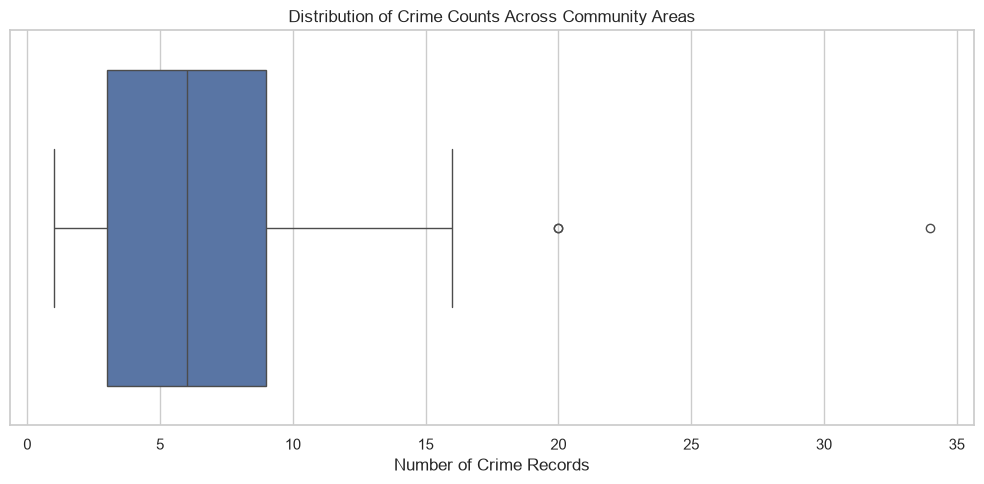

In [12]:
# Identify community areas outside the IQR boundaries
outliers = community_stats[
    (community_stats["Crime_Count"] < lower_bound) |
    (community_stats["Crime_Count"] > upper_bound)
].copy()

print("Number of outlier community areas:", len(outliers))

display(
    outliers.sort_values(
        "Crime_Count",
        ascending=False
    ).reset_index(drop=True)
)

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=community_stats["Crime_Count"]
)

plt.title("Distribution of Crime Counts Across Community Areas")
plt.xlabel("Number of Crime Records")

plt.tight_layout()
plt.show()

### Community Area Outlier Analysis Using the IQR Method

The Interquartile Range (IQR) method was applied to identify community areas with unusually high crime counts.

The first quartile (Q1) was 3, and the third quartile (Q3) was 9, resulting in an IQR of 6. The calculated lower and upper boundaries were -6 and 18, respectively.

Three community areas were identified as upper outliers:

- Austin (Community Code 25): 34 crime records
- Humboldt Park (Community Code 23): 20 crime records
- Near North Side (Community Code 8): 20 crime records

These areas recorded substantially more incidents than the upper IQR boundary. Austin had the highest count.

These are statistical outliers within the available sample of 498 records. They should not automatically be interpreted as areas with the highest underlying crime risk, since population size, reporting patterns, and sample coverage may influence the counts.

Correlation analysis among numerical values and calculate the correlation matrix

In [15]:
# Select numeric columns for correlation analysis
numeric_df = stats_df.select_dtypes(
    include=["number"]
).copy()

print("Numeric columns:")
print(numeric_df.columns.tolist())

display(numeric_df.head())

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

print("Correlation matrix:")
display(correlation_matrix)

Numeric columns:
['ward_no', 'latitude', 'longitude', 'year', 'Month', 'Year', 'Hour']


,ward_no,latitude,longitude,year,Month,Year,Hour
0,24,41.864073,-87.706819,2016,5,2016,0
1,20,41.782922,-87.604363,2016,5,2016,0
2,37,41.894908,-87.758372,2016,5,2016,0
3,28,41.885687,-87.749516,2016,5,2016,0
4,28,41.886297,-87.761751,2016,5,2016,0


Correlation matrix:


,ward_no,latitude,longitude,year,Month,Year,Hour
ward_no,1.000000,0.696503,-0.477399,-0.056432,-0.050146,-0.056432,NaN
latitude,0.696503,1.000000,-0.562283,-0.037807,-0.107203,-0.037807,NaN
longitude,-0.477399,-0.562283,1.000000,0.051529,0.000752,0.051529,NaN
year,-0.056432,-0.037807,0.051529,1.000000,0.149759,1.000000,NaN
Month,-0.050146,-0.107203,0.000752,0.149759,1.000000,0.149759,NaN
Year,-0.056432,-0.037807,0.051529,1.000000,0.149759,1.000000,NaN
Hour,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Create the correlation heatmap

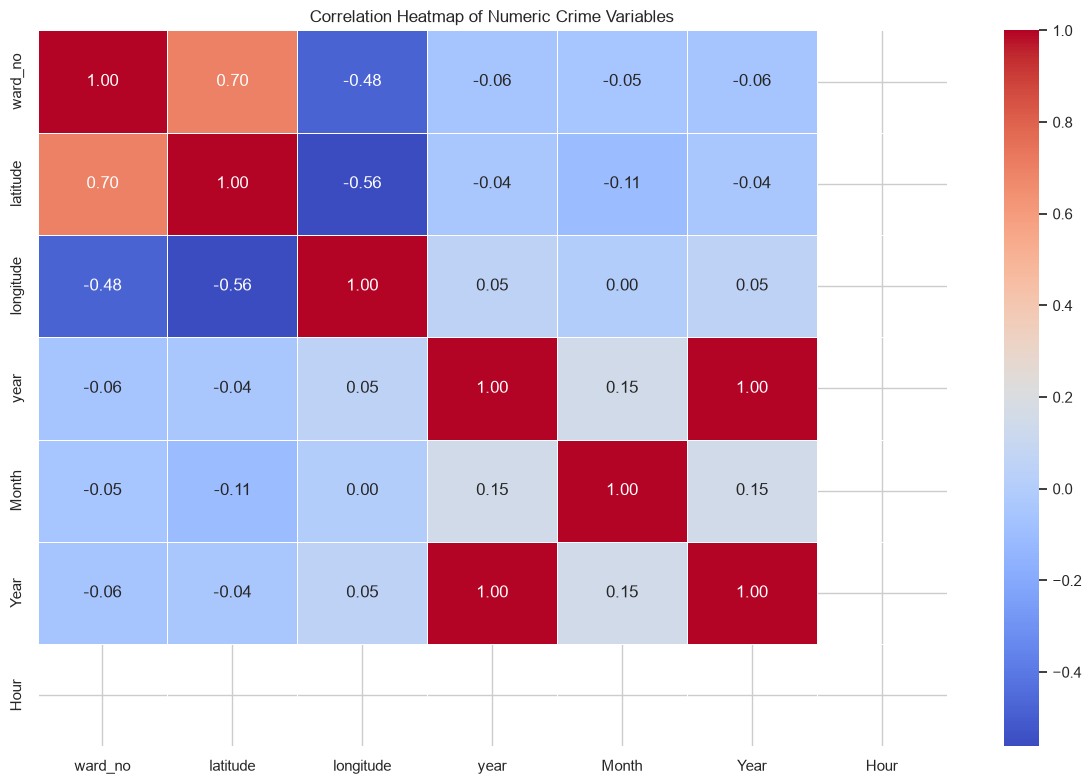

In [16]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Crime Variables")

plt.tight_layout()
plt.show()

The correlation analysis showed positive association between ward number and latitude (+0.697), and negative associations between latitude and longitude (-0.562) and ward number and longitude (-0.477). However, these relationships do not indicate crime risk or causation. The `Hour` variable produced `NaN` correlations because all records had an hour value of 0 due to missing time information. Also, `year` and `Year` contained identical information, resulting in a perfect correlation (+1.00). Therefore, we excluded the duplicate year, constant hour, and identifier fields from the revised correlation analysis.

Prepare meaningful numeric  and correlation matrix

In [17]:
# Convert Boolean variables into numeric values
stats_df["arrest_numeric"] = stats_df["arrest"].map({
    True: 1, False: 0,
    1: 1, 0: 0,
    "1": 1, "0": 0
})

stats_df["domestic_numeric"] = stats_df["domestic"].map({
    True: 1, False: 0,
    1: 1, 0: 0,
    "1": 1, "0": 0
})

# Select meaningful numeric variables
correlation_data = stats_df[
    [
        "latitude",
        "longitude",
        "year",
        "Month",
        "arrest_numeric",
        "domestic_numeric"
    ]
].copy()

print("Variables selected for correlation analysis:")
print(correlation_data.columns.tolist())

display(correlation_data.head())


correlation_matrix = correlation_data.corr(
    method="pearson"
)

display(correlation_matrix)

Variables selected for correlation analysis:
['latitude', 'longitude', 'year', 'Month', 'arrest_numeric', 'domestic_numeric']


,latitude,longitude,year,Month,arrest_numeric,domestic_numeric
0,41.864073,-87.706819,2016,5,1,1
1,41.782922,-87.604363,2016,5,0,1
2,41.894908,-87.758372,2016,5,0,0
3,41.885687,-87.749516,2016,5,0,0
4,41.886297,-87.761751,2016,5,0,1


,latitude,longitude,year,Month,arrest_numeric,domestic_numeric
latitude,1.000000,-0.562283,-0.037807,-0.107203,-0.011159,0.008061
longitude,-0.562283,1.000000,0.051529,0.000752,-0.028251,-0.025450
year,-0.037807,0.051529,1.000000,0.149759,-0.130560,0.024781
Month,-0.107203,0.000752,0.149759,1.000000,-0.175629,0.029783
arrest_numeric,-0.011159,-0.028251,-0.130560,-0.175629,1.000000,0.014447
domestic_numeric,0.008061,-0.025450,0.024781,0.029783,0.014447,1.000000


Create the revised heatmap

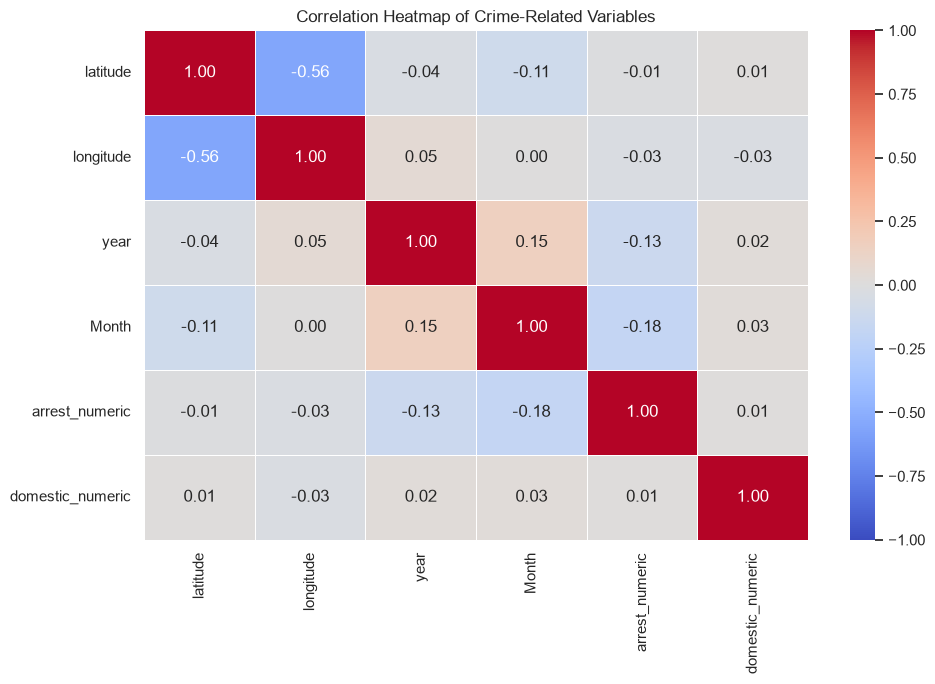

In [18]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Crime-Related Variables")

plt.tight_layout()
plt.show()

### Correlation Analysis – Interpretation and Limitations

A Pearson correlation analysis was performed on selected numeric variables, including geographic coordinates, year, month, arrest status, and domestic incident status.

The original correlation analysis showed associations between ward numbers and geographic coordinates. However, these variables are identifiers or location measurements rather than direct measures of crime frequency.

The hour variable was excluded because the dataset does not contain actual occurrence times. The original year column and derived Year column were also duplicates, so only one was retained.

Correlation coefficients indicate linear associations and do not establish causal relationships. The findings should be interpreted cautiously because the dataset contains only 498 records and is heavily concentrated in May 2016.